## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 30, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

In [5]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "tchoud227"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

# Change the working directory to the specific assignment folder within the cloned repository
setwd(file.path(repo_name, "Assignments", "HW3"))

In [6]:
getwd()

[1] "/content/STAT-7110-Quality-Control/Assignments/HW3/STAT-7110-Quality-Control/Assignments/HW3"

In [12]:
install.packages(c("tidyverse", "readxl", "qcc", "ggplot2"))

library(tidyverse)
library(readxl)
library(qcc)
library(ggplot2)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [8]:
## Q4 Code ##
df_A <- read_excel("RavisComics_ShipmentCondition_PhaseI.xlsx")
df_A |> glimpse()



Rows: 25
Columns: 3
$ Week                <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ TotalComics         <dbl> 194, 216, 149, 142, 124, 212, 144, 117, 187, 201, …
$ NumberNonconforming <dbl> 7, 8, 6, 8, 5, 17, 11, 2, 9, 8, 9, 11, 9, 74, 7, 6…


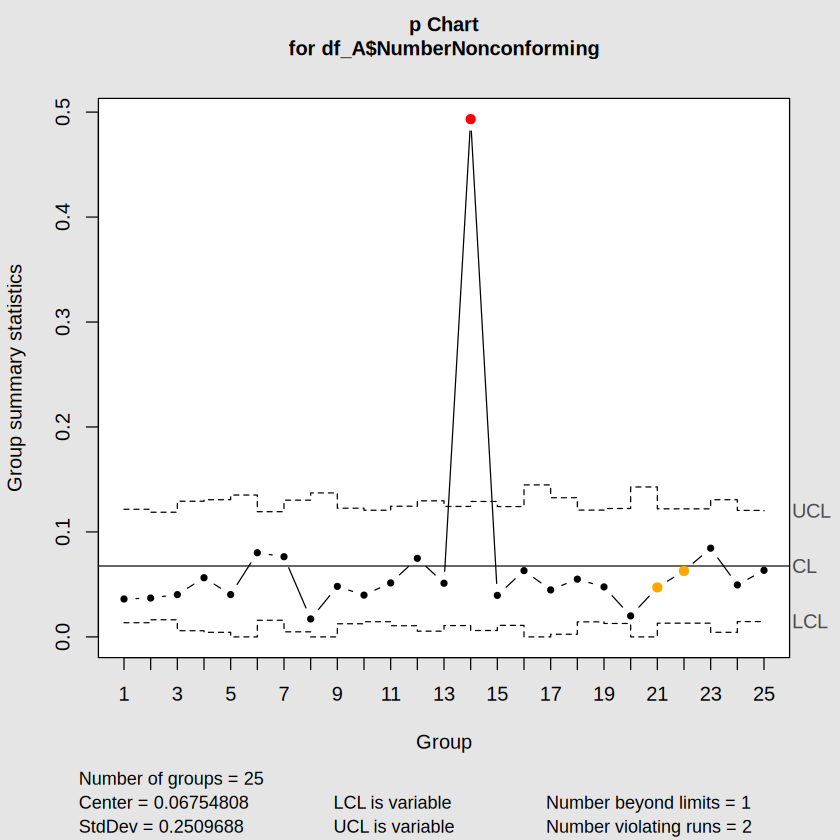

In [9]:
#phase 1 p-chart
ship_Cond <- qcc(df_A$NumberNonconforming,
                 type ="p",
                 sizes = df_A$TotalComics,
                 plot = TRUE)

The chart does not show statistical control as week 14 has an point beyond the upper control limit. As well as some patterning on a couple of runs. Specifically week 21 & 23. Going to try omitting week 14 first to see if that establishes statistical control.

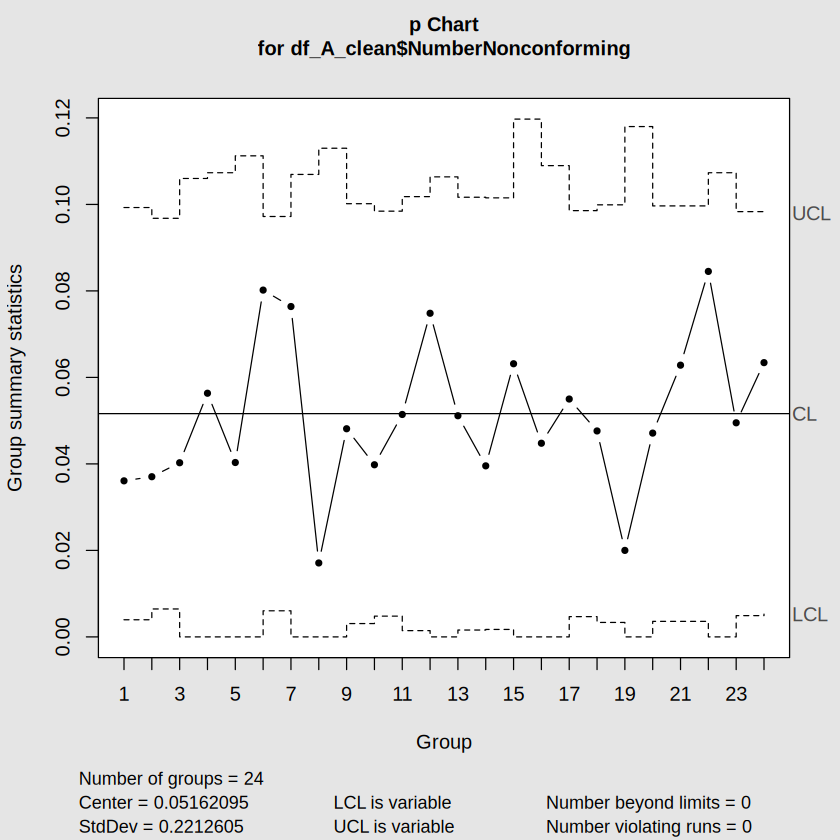

In [10]:
#omitting week 14
df_A_clean <- df_A |> slice(-14)
ship_Cond_clean <- qcc(df_A_clean$NumberNonconforming,
                 type ="p",
                 sizes = df_A_clean$TotalComics,
                 plot = TRUE)

After omitting week 14, the chart shows statistical control as there is no points outside the limits or some sort of pattern. No violations.

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

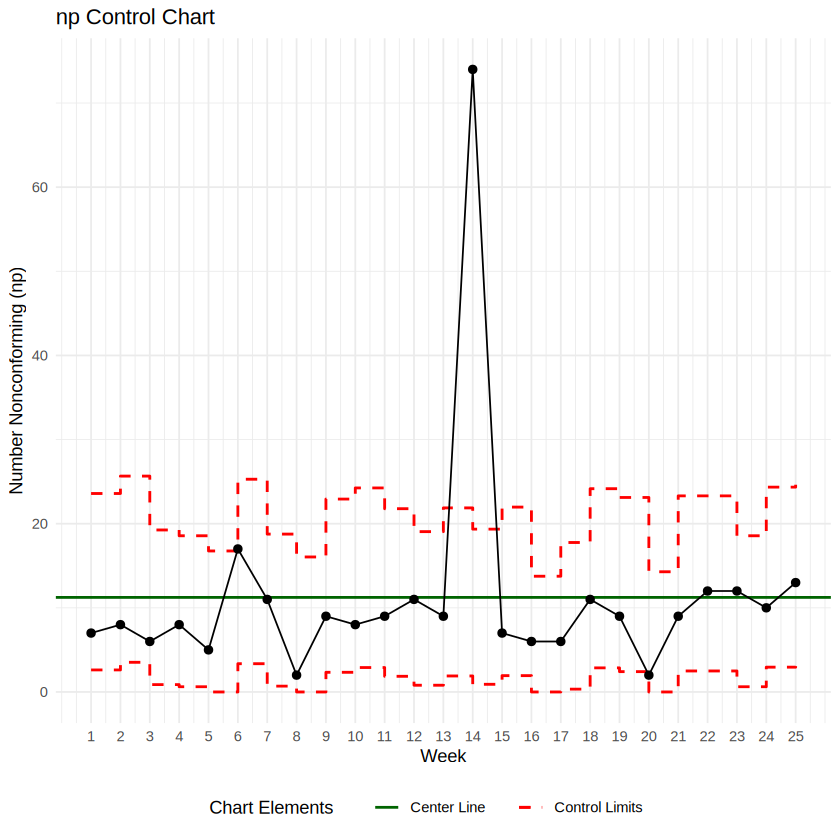

In [24]:
## Q5 Code ##
# I prompted gemini to construct a np chart with the slide formulas for UCL & LCL using ggplot2.
# For the most part it was good besides the center line calculation.
# Had to adjust the n as it was orginally just multiplying the varying sizes. Instead I added the average of the varying sizes instead.

df_chart <- df_A |>
  mutate(Sample = row_number()) |>
  mutate(
    p_bar = sum(NumberNonconforming) / sum(TotalComics),
    n_bar = mean(TotalComics),

    CL = n_bar * p_bar, #before was TotalComics * p_bar

    UCL = (TotalComics * p_bar) + 3 * sqrt((TotalComics * p_bar) * (1 - p_bar)),
    LCL = pmax(0, (TotalComics * p_bar) - 3 * sqrt((TotalComics * p_bar) * (1 - p_bar)))
  )

ggplot(df_chart, aes(x = Sample)) +
  geom_step(aes(y = UCL, color = "Control Limits"), linetype = "dashed", linewidth = 0.8) +
  geom_step(aes(y = LCL, color = "Control Limits"), linetype = "dashed", linewidth = 0.8) +
  geom_hline(aes(yintercept = CL, color = "Center Line"), linetype = "solid", linewidth = 0.8) +
  geom_line(aes(y = NumberNonconforming), color = "black", linewidth = 0.5) +
  geom_point(aes(y = NumberNonconforming), color = "black", size = 2) +
  scale_color_manual(name = "Chart Elements",
                     values = c("Control Limits" = "red", "Center Line" = "darkgreen")) +
  scale_x_continuous(breaks = 1:25) +
  labs(
    title = "np Control Chart",
    x = "Week",
    y = "Number Nonconforming (np)"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")


Not exactly as the it is still just week 14 that is statistically out of control. However there are a few points on the limit but not past it now. Such as week 6 & 20. They're not past the limit but much closer compared to the p-chart.

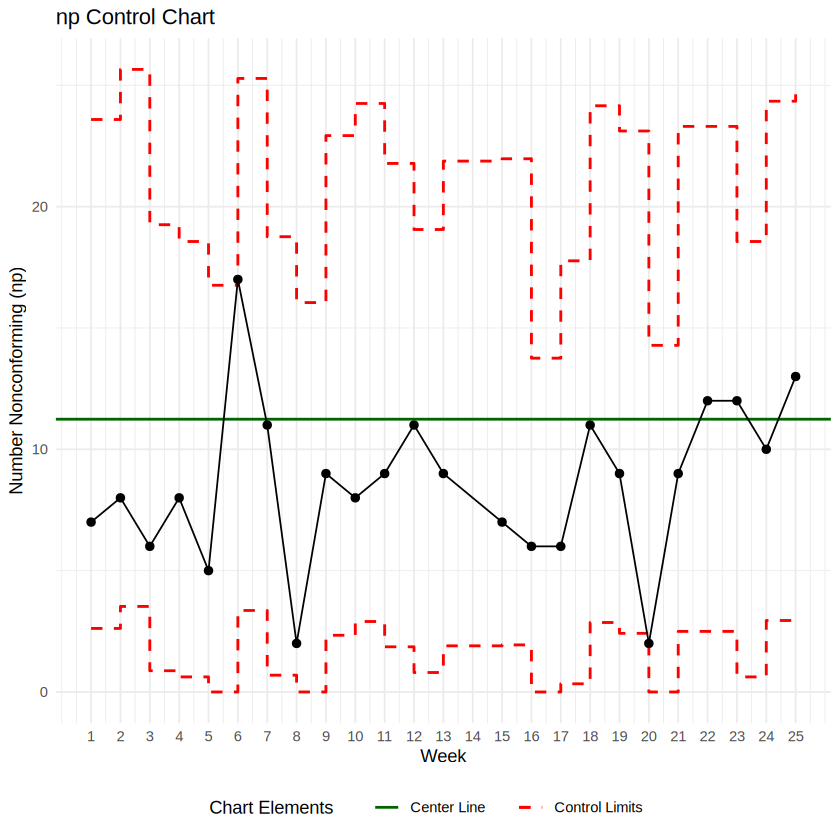

In [26]:
# omitting week 14 with ggplot2 & tidy
df_chart_clean <- df_chart |> filter(Sample != 14)

ggplot(df_chart_clean, aes(x = Sample)) +
  geom_step(aes(y = UCL, color = "Control Limits"), linetype = "dashed", linewidth = 0.8) +
  geom_step(aes(y = LCL, color = "Control Limits"), linetype = "dashed", linewidth = 0.8) +
  geom_hline(aes(yintercept = CL, color = "Center Line"), linetype = "solid", linewidth = 0.8) +
  geom_line(aes(y = NumberNonconforming), color = "black", linewidth = 0.5) +
  geom_point(aes(y = NumberNonconforming), color = "black", size = 2) +
  scale_color_manual(name = "Chart Elements",
                     values = c("Control Limits" = "red", "Center Line" = "darkgreen")) +
  scale_x_continuous(breaks = 1:25) +
  labs(
    title = "np Control Chart",
    x = "Week",
    y = "Number Nonconforming (np)"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")

We no longer have a ooc point. There are some points touching the limits but not past it, so I would say the chart is in statistical control.

From the scenario, it was noted that the distributor account representative thinks in countable books instead of fractions/percentages. This means np chart would be better here as that uses the raw count while p chart uses percentages.

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

In [37]:
## Q6 Code ##
#Going to be using np chart for center line & limits

phaseII_limits <- df_chart_clean |>
  summarise(
    p_bar = sum(NumberNonconforming) / sum(TotalComics),
    n_bar = mean(TotalComics),

    CL_np  = n_bar * p_bar,
    UCL_np = CL_np + 3 * sqrt(CL_np * (1 - p_bar)),
    LCL_np = pmax(0, CL_np - 3 * sqrt(CL_np * (1 - p_bar)))
  )

print(phaseII_limits)


# A tibble: 1 × 5
   p_bar n_bar CL_np UCL_np LCL_np
   <dbl> <dbl> <dbl>  <dbl>  <dbl>
1 0.0516  167.  8.63   17.2 0.0449


## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

In [ ]:
## Q8 Code ##

### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

In [ ]:
## Q9 Code ##

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

In [ ]:
## Q10 Code ##

### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

In [ ]:
## Q11 Code ##

### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

In [ ]:
## Q12 Code ##

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?